In [1]:
import matplotlib.pyplot as plt
from time import perf_counter
from tqdm import tqdm
import math

import sys
sys.setrecursionlimit(1000000)

# Exercice 1

In [2]:
def suite_fibonacci_dynamique(n):
    valeurs_suite = [0]

    if n > 0:
        valeurs_suite.append(1)
    
    for i in range(2, n + 1):
        valeurs_suite.append(valeurs_suite[i - 1] + valeurs_suite[i - 2])

    return valeurs_suite[-1]

In [3]:
taille_mesure = 5000
temps_mesures = []

for i in tqdm(range(taille_mesure)):
    debut = perf_counter()
    suite_fibonacci_dynamique(i)
    temps_mesures.append(perf_counter() - debut)

100%|█████████████████████████████████████| 5000/5000 [00:01<00:00, 4233.01it/s]


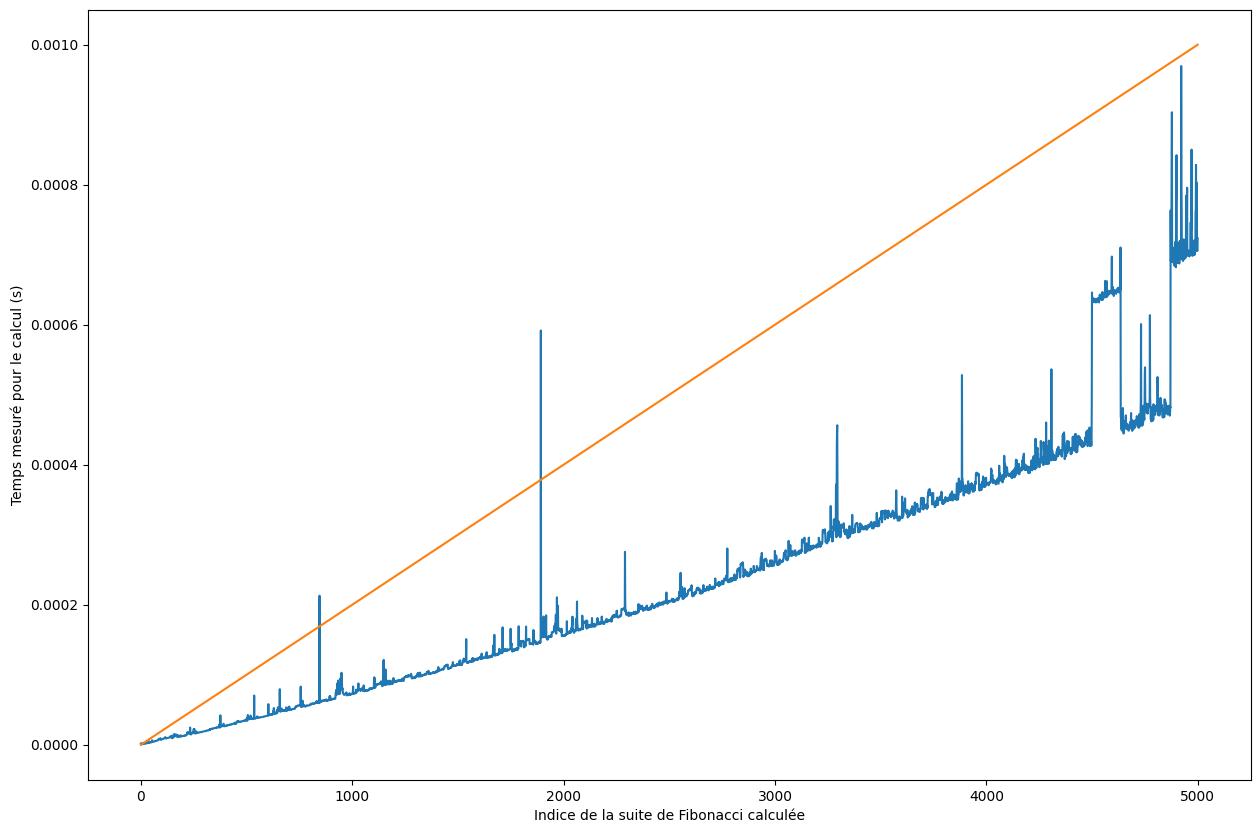

In [4]:
plt.figure(figsize=(15, 10))
plt.plot([i for i in range(taille_mesure)], temps_mesures)
plt.plot([i for i in range(taille_mesure)], [2e-7 * k for k in range(taille_mesure)])
plt.xlabel("Indice de la suite de Fibonacci calculée")
plt.ylabel("Temps mesuré pour le calcul (s)")
plt.show()

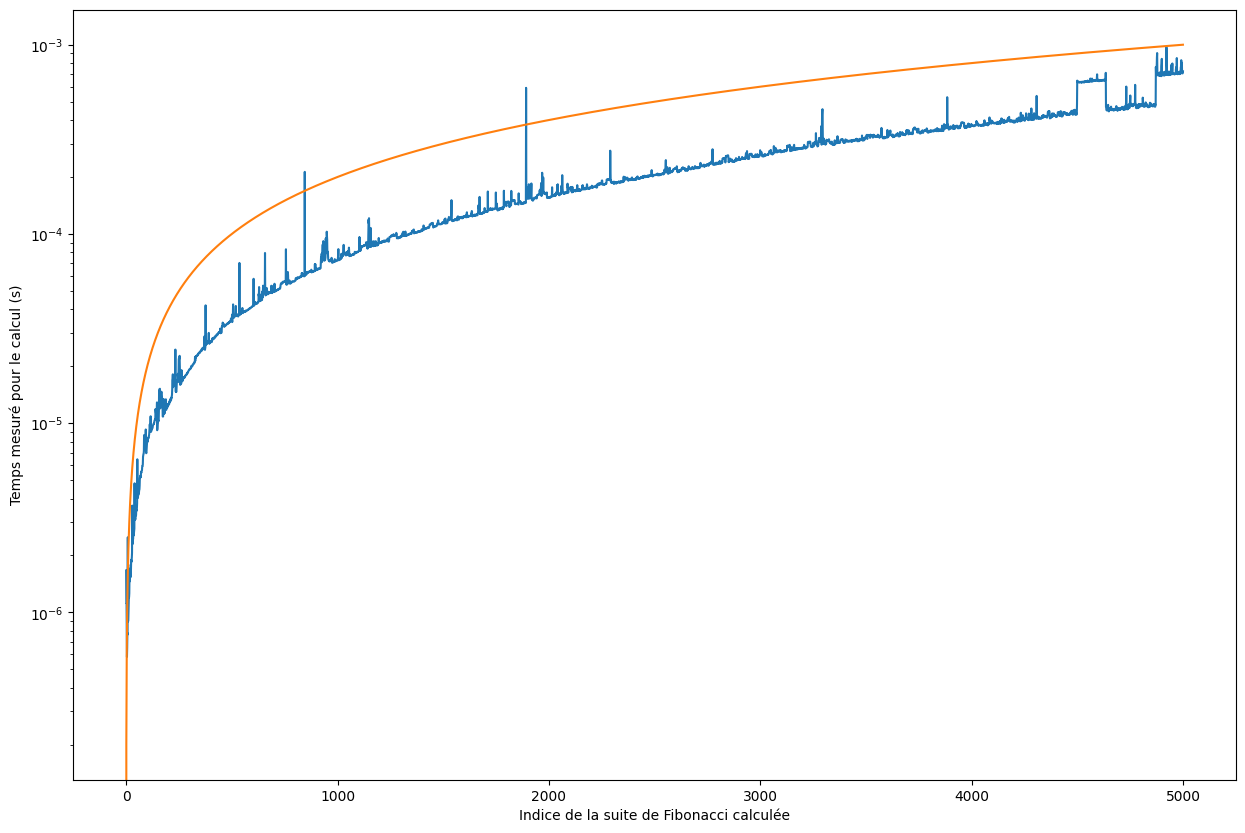

In [5]:
plt.figure(figsize=(15, 10))
plt.plot([i for i in range(taille_mesure)], temps_mesures)
plt.plot([i for i in range(taille_mesure)], [2e-7 * k for k in range(taille_mesure)])
plt.xlabel("Indice de la suite de Fibonacci calculée")
plt.ylabel("Temps mesuré pour le calcul (s)")
plt.yscale('log')
plt.show()

# Exercice 2

In [6]:
def nombre_minimal_pieces_memoisation(P, S, k, structure_memoisation):
    key = (str(S), str(k))
    
    if key in structure_memoisation:
        return structure_memoisation[key]

    if S == 0:
        structure_memoisation[key] = 0
    elif (k == -1 and S >= 0) or S < 0:
        structure_memoisation[key] = math.inf
            
    else:
        structure_memoisation[key] = min(nombre_minimal_pieces_memoisation(P, S, k-1, structure_memoisation), 1 + nombre_minimal_pieces_memoisation(P, S - P[k], k, structure_memoisation))
    return structure_memoisation[key]

In [7]:
P_euro = [1, 2, 5, 10, 20, 50, 100, 200]
k = len(P_euro) - 1

print(nombre_minimal_pieces_memoisation(P_euro, 0, k, dict()))
print(nombre_minimal_pieces_memoisation(P_euro, 2, -1, dict()))
print(nombre_minimal_pieces_memoisation(P_euro, 1301, k, dict()))
print(nombre_minimal_pieces_memoisation(P_euro, 13, 2, dict()))
print(nombre_minimal_pieces_memoisation(P_euro, 113, 2, dict()))

0
inf
8
4
24


# Exercice 3

In [8]:
def nombre_minimal_pieces_memoisation_retour_structure(P, S, k, structure_memoisation):
    key = (str(S), str(k))
    
    if key in structure_memoisation:
        return key, structure_memoisation

    result = None
    if S == 0:
        structure_memoisation[key] = {'min_val':0, 'sous_struct':None}
    elif (k == -1 and S >= 0) or S < 0:
        structure_memoisation[key] = {'min_val':math.inf, 'sous_struct':None}
            
    else:
        left_key, left_memoisation = nombre_minimal_pieces_memoisation_retour_structure(P, S, k-1, structure_memoisation)
        right_key, right_memoisation = nombre_minimal_pieces_memoisation_retour_structure(P, S - P[k], k, structure_memoisation)
        
        min_key = None
        min_val = None
        if left_memoisation[left_key]['min_val'] < 1 + right_memoisation[right_key]['min_val']:
            min_key = left_key
            min_val = left_memoisation[left_key]['min_val']
        else:
            min_key = right_key
            min_val = 1 + right_memoisation[right_key]['min_val']

        structure_memoisation[key] = {'min_val':min_val, 'sous_struct':min_key}
    return key, structure_memoisation

def nombre_minimal_pieces_memoisation_avec_combinaison(P, S, k):
    combinaison = [-1 for i in range(k + 1)]
    key, memoisation = nombre_minimal_pieces_memoisation_retour_structure(P, S, k, dict())
    
    valeur_min = memoisation[key]['min_val']
    next_key = key

    while next_key is not None:
        indice_combinaison = int(next_key[1])
        combinaison[indice_combinaison] += 1
        next_key = memoisation[next_key]['sous_struct']
        
    return valeur_min, combinaison

In [9]:
valeurs_S = [1301, 113]
valeurs_k = [k, 2]

for idx in range(len(valeurs_S)):

    min_val, combinaison = nombre_minimal_pieces_memoisation_avec_combinaison(P_euro, valeurs_S[idx], valeurs_k[idx])
    print("Problème : rendre la monnaie sur " + str(valeurs_S[idx]) + " unités de monnaie avec un nombre minimal de pièces en utilisant le système monétaire " + str(P_euro[:valeurs_k[idx]+1]) + ".\n")
    print("Nombre minimal de pièces trouvé : " + str(min_val) + ", réparties comme suit.")
    for idx2 in range(valeurs_k[idx] + 1):
        if combinaison[idx2] == -1:
            print("*\tLa pièce ayant pour valeur " + str(P_euro[idx2]) + " n'est pas utilisée dans ce cas.")
        else:
            print("*\tLa pièce ayant pour valeur " + str(P_euro[idx2]) + " est utilisée " + str(combinaison[idx2]) + " fois.")
    print("\n")

Problème : rendre la monnaie sur 1301 unités de monnaie avec un nombre minimal de pièces en utilisant le système monétaire [1, 2, 5, 10, 20, 50, 100, 200].

Nombre minimal de pièces trouvé : 8, réparties comme suit.
*	La pièce ayant pour valeur 1 est utilisée 1 fois.
*	La pièce ayant pour valeur 2 est utilisée 0 fois.
*	La pièce ayant pour valeur 5 est utilisée 0 fois.
*	La pièce ayant pour valeur 10 est utilisée 0 fois.
*	La pièce ayant pour valeur 20 est utilisée 0 fois.
*	La pièce ayant pour valeur 50 est utilisée 0 fois.
*	La pièce ayant pour valeur 100 est utilisée 1 fois.
*	La pièce ayant pour valeur 200 est utilisée 6 fois.


Problème : rendre la monnaie sur 113 unités de monnaie avec un nombre minimal de pièces en utilisant le système monétaire [1, 2, 5].

Nombre minimal de pièces trouvé : 24, réparties comme suit.
*	La pièce ayant pour valeur 1 est utilisée 1 fois.
*	La pièce ayant pour valeur 2 est utilisée 1 fois.
*	La pièce ayant pour valeur 5 est utilisée 22 fois.


